In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [32]:
#PLT 한글 깨짐 방지코드
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

In [31]:
#실습1

In [37]:
data_path = "C:\\AI Equipment Failure Prediction\\data\\23_전기panel.csv"
df = pd.read_csv(data_path)

In [38]:
df.shape
df.head()

,설비번호,시퀀스,컨베이어전류,회전A전류,회전B전류,펌프A전류,펌프B전류
0,1,1,0.0,0.0523,0.7037,0.0125,0.0
1,1,2,0.0,0.0523,0.7037,0.0115,0.0
2,1,3,0.0,0.0523,0.7037,0.0102,0.0
3,1,4,0.0,0.0523,0.7037,0.0100,0.0
4,1,5,0.0,0.0523,0.7037,0.0100,0.0


In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1250 entries, 0 to 1249
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   설비번호    1250 non-null   int64  
 1   시퀀스     1250 non-null   int64  
 2   컨베이어전류  1250 non-null   float64
 3   회전A전류   1250 non-null   float64
 4   회전B전류   1250 non-null   float64
 5   펌프A전류   1250 non-null   float64
 6   펌프B전류   1250 non-null   float64
dtypes: float64(5), int64(2)
memory usage: 68.5 KB


In [42]:
u2 = df[df['설비번호'] == 2].copy().sort_values('시퀀스').reset_index(drop=True)

In [44]:
u1 = df[df['설비번호'] == 1].copy().sort_values('시퀀스').reset_index(drop=True)

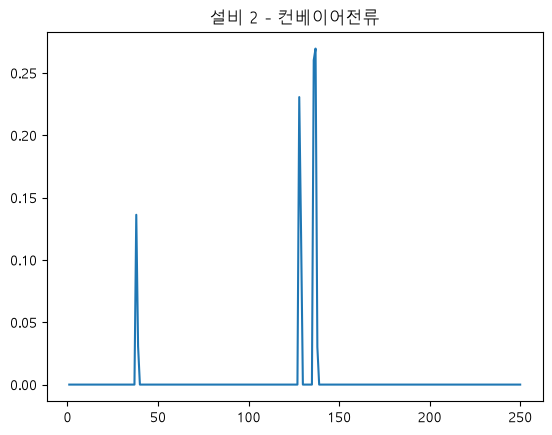

In [43]:
plt.plot(u2['시퀀스'], u2['컨베이어전류'])
plt.title('설비 2 - 컨베이어전류')
plt.show()

In [46]:
u1['MA10'] = u1['컨베이어전류'].rolling(window=10).mean()
u1

,설비번호,시퀀스,컨베이어전류,회전A전류,회전B전류,펌프A전류,펌프B전류,MA10
0,1,1,0.0000,0.0523,0.7037,0.0125,0.0,NaN
1,1,2,0.0000,0.0523,0.7037,0.0115,0.0,NaN
2,1,3,0.0000,0.0523,0.7037,0.0102,0.0,NaN
3,1,4,0.0000,0.0523,0.7037,0.0100,0.0,NaN
4,1,5,0.0000,0.0523,0.7037,0.0100,0.0,NaN
...,...,...,...,...,...,...,...,...
245,1,246,0.2482,0.0500,0.7030,0.0100,0.0,0.13979
246,1,247,0.2482,0.0509,0.7037,0.0100,0.0,0.13908
247,1,248,0.2485,0.0509,0.7037,0.0100,0.0,0.13840
248,1,249,0.2489,0.0512,0.7037,0.0100,0.0,0.13776


In [47]:
#잔차 resuuals : 평균의 차

In [49]:
residuals_1 = u1['컨베이어전류'] - u1['MA10']
u1

,설비번호,시퀀스,컨베이어전류,회전A전류,회전B전류,펌프A전류,펌프B전류,MA10,residuals
0,1,1,0.0000,0.0523,0.7037,0.0125,0.0,NaN,NaN
1,1,2,0.0000,0.0523,0.7037,0.0115,0.0,NaN,NaN
2,1,3,0.0000,0.0523,0.7037,0.0102,0.0,NaN,NaN
3,1,4,0.0000,0.0523,0.7037,0.0100,0.0,NaN,NaN
4,1,5,0.0000,0.0523,0.7037,0.0100,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...
245,1,246,0.2482,0.0500,0.7030,0.0100,0.0,0.13979,0.10841
246,1,247,0.2482,0.0509,0.7037,0.0100,0.0,0.13908,0.10912
247,1,248,0.2485,0.0509,0.7037,0.0100,0.0,0.13840,0.11010
248,1,249,0.2489,0.0512,0.7037,0.0100,0.0,0.13776,0.11114


In [55]:
thr1 = 2*residuals_1.std() # 임계치 잡기

In [52]:
residuals_1.abs() > thr1

0      False
1      False
2      False
3      False
4      False
       ...  
245     True
246     True
247     True
248     True
249     True
Length: 250, dtype: bool

In [53]:
residuals_1[residuals_1.abs() > thr1]

223    0.22205
224    0.19979
225    0.17257
226    0.14414
227    0.11861
228    0.09272
239   -0.20331
240   -0.20718
241   -0.18165
242   -0.15612
244    0.10770
245    0.10841
246    0.10912
247    0.11010
248    0.11114
249    0.08856
dtype: float64

In [54]:
len(residuals_1[residuals_1.abs() > thr1])

16

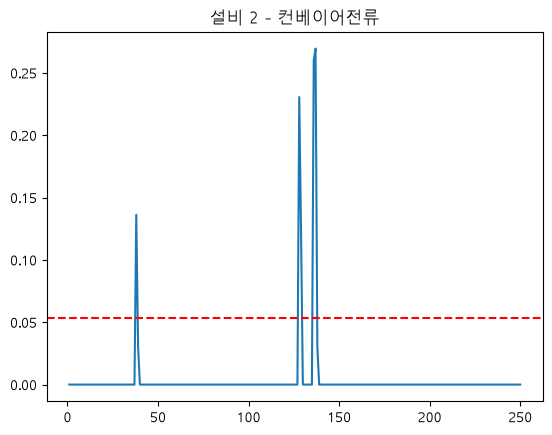

In [74]:
plt.plot(u2['시퀀스'], u2['컨베이어전류'])
plt.axhline(y=thr2, color='r', linestyle='--')
plt.title('설비 2 - 컨베이어전류')
plt.show()

In [58]:
u2['MA10'] = u2['컨베이어전류'].rolling(window=10).mean()
u2

,설비번호,시퀀스,컨베이어전류,회전A전류,회전B전류,펌프A전류,펌프B전류,MA10
0,2,1,0.0,0.0496,0.7037,0.0,0.0,NaN
1,2,2,0.0,0.0496,0.7037,0.0,0.0,NaN
2,2,3,0.0,0.0496,0.7037,0.0,0.0,NaN
3,2,4,0.0,0.0496,0.7037,0.0,0.0,NaN
4,2,5,0.0,0.0496,0.7037,0.0,0.0,NaN
...,...,...,...,...,...,...,...,...
245,2,246,0.0,0.0523,0.7037,0.0,0.0,0.0
246,2,247,0.0,0.0523,0.7037,0.0,0.0,0.0
247,2,248,0.0,0.0523,0.7037,0.0,0.0,0.0
248,2,249,0.0,0.0523,0.7037,0.0,0.0,0.0


In [ ]:
residuals_1[residuals_1.abs() > thr1]

In [60]:
residuals_2 = u2['컨베이어전류'] - u2['MA10']
u2

,설비번호,시퀀스,컨베이어전류,회전A전류,회전B전류,펌프A전류,펌프B전류,MA10
0,2,1,0.0,0.0496,0.7037,0.0,0.0,NaN
1,2,2,0.0,0.0496,0.7037,0.0,0.0,NaN
2,2,3,0.0,0.0496,0.7037,0.0,0.0,NaN
3,2,4,0.0,0.0496,0.7037,0.0,0.0,NaN
4,2,5,0.0,0.0496,0.7037,0.0,0.0,NaN
...,...,...,...,...,...,...,...,...
245,2,246,0.0,0.0523,0.7037,0.0,0.0,0.0
246,2,247,0.0,0.0523,0.7037,0.0,0.0,0.0
247,2,248,0.0,0.0523,0.7037,0.0,0.0,0.0
248,2,249,0.0,0.0523,0.7037,0.0,0.0,0.0


In [61]:
thr2 = 2*residuals_2.std() # 임계치 잡기

In [ ]:
residuals_2.abs() > thr2

In [ ]:
residuals_2[residuals_2.abs() > thr2]

In [67]:
len(residuals_2[residuals_2.abs() > thr2])

12

In [75]:
#실습2

In [76]:
u2.head()

,설비번호,시퀀스,컨베이어전류,회전A전류,회전B전류,펌프A전류,펌프B전류,MA10
0,2,1,0.0,0.0496,0.7037,0.0,0.0,NaN
1,2,2,0.0,0.0496,0.7037,0.0,0.0,NaN
2,2,3,0.0,0.0496,0.7037,0.0,0.0,NaN
3,2,4,0.0,0.0496,0.7037,0.0,0.0,NaN
4,2,5,0.0,0.0496,0.7037,0.0,0.0,NaN


In [80]:
u2['컨베이어 MA10'] = u2['컨베이어전류'].rolling(window=10).mean()
u2.head()

,설비번호,시퀀스,컨베이어전류,회전A전류,회전B전류,펌프A전류,펌프B전류,MA10,컨베이어 MA10
0,2,1,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN
1,2,2,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN
2,2,3,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN
3,2,4,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN
4,2,5,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN


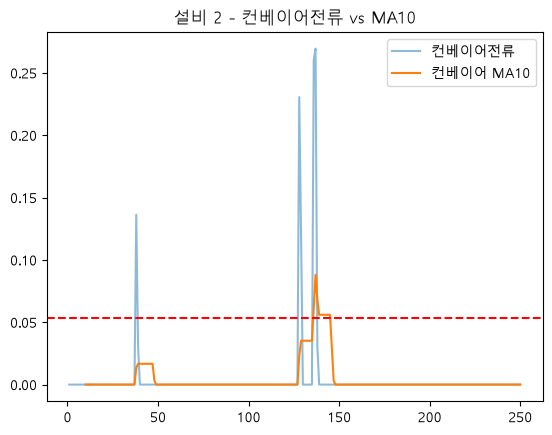

In [86]:
plt.plot(u2['시퀀스'], u2['컨베이어전류'], label='컨베이어전류', alpha=0.5)
plt.plot(u2['시퀀스'], u2['컨베이어 MA10'], label='컨베이어 MA10')
plt.axhline(y=thr2, color='r', linestyle='--')
plt.title('설비 2 - 컨베이어전류 vs MA10')
plt.legend()
plt.show()

In [89]:
#실습3

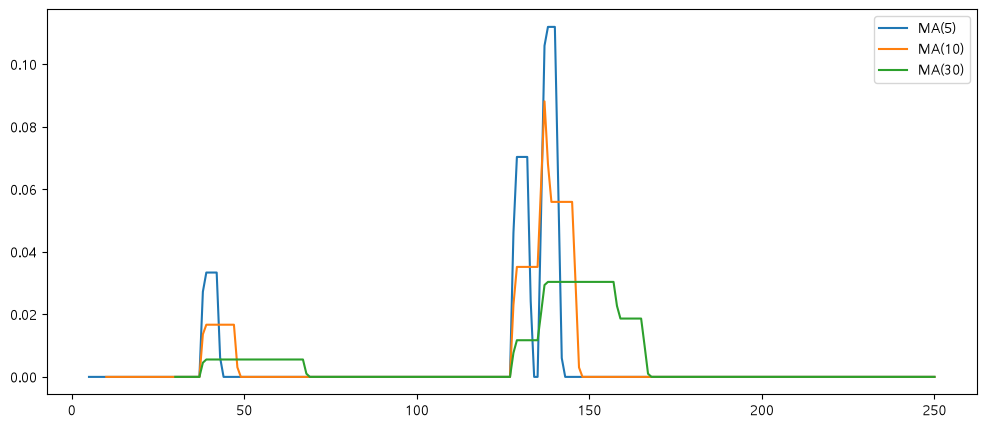

In [99]:
plt.figure(figsize=(12, 5))
for i in [5, 10, 30]:
    plt.plot(u2['시퀀스'], u2['컨베이어전류'].rolling(window=i).mean(), label=f'MA({i})')
plt.legend()
plt.show()

In [100]:
#실습4

In [101]:
u2

,설비번호,시퀀스,컨베이어전류,회전A전류,회전B전류,펌프A전류,펌프B전류,MA10,컨베이어 MA10
0,2,1,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN
1,2,2,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN
2,2,3,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN
3,2,4,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN
4,2,5,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...
245,2,246,0.0,0.0523,0.7037,0.0,0.0,0.0,0.0
246,2,247,0.0,0.0523,0.7037,0.0,0.0,0.0,0.0
247,2,248,0.0,0.0523,0.7037,0.0,0.0,0.0,0.0
248,2,249,0.0,0.0523,0.7037,0.0,0.0,0.0,0.0


In [103]:
u2['컨베이어전류_rolling_std'] = u2['컨베이어전류'].rolling(window=10).std()
u2.head()


,설비번호,시퀀스,컨베이어전류,회전A전류,회전B전류,펌프A전류,펌프B전류,MA10,컨베이어 MA10,컨베이어전류_rolling_std
0,2,1,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN,NaN
1,2,2,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN,NaN
2,2,3,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN,NaN
3,2,4,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN,NaN
4,2,5,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN,NaN


In [107]:
print(u2['컨베이어 MA10'].iloc[10:50].mean())

0.0041725


In [108]:
early = u2['컨베이어전류_rolling_std'].iloc[10:50].mean()
late = u2['컨베이어전류_rolling_std'].iloc[150:].mean()
print('초반 /후반  변동성 :', round(early, 4), round(late, 4))   # 0.011 / 0.0

초반 /후반  변동성 : 0.011 0.0


In [109]:
#실습5

In [112]:
u2['컨베이어전류'].diff()

0      NaN
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
245    0.0
246    0.0
247    0.0
248    0.0
249    0.0
Name: 컨베이어전류, Length: 250, dtype: float64

In [118]:
u2['컨베이어전류'].diff().abs().max()

np.float64(0.2602)

In [117]:
u2['컨베이어전류'].diff().abs().idxmax()

135

In [113]:
u2['컨베이어 MA10'].diff()

0      NaN
1      NaN
2      NaN
3      NaN
4      NaN
      ... 
245    0.0
246    0.0
247    0.0
248    0.0
249    0.0
Name: 컨베이어 MA10, Length: 250, dtype: float64

In [115]:
u2['컨베이어 MA10'].diff().max().round(4)

np.float64(0.0269)

In [119]:
#실습6

In [121]:
u2.head()

,설비번호,시퀀스,컨베이어전류,회전A전류,회전B전류,펌프A전류,펌프B전류,MA10,컨베이어 MA10,컨베이어전류_rolling_std
0,2,1,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN,NaN
1,2,2,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN,NaN
2,2,3,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN,NaN
3,2,4,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN,NaN
4,2,5,0.0,0.0496,0.7037,0.0,0.0,NaN,NaN,NaN


In [123]:
잔차 = u2['컨베이어전류'] - u2['컨베이어 MA10']
잔차

0      NaN
1      NaN
2      NaN
3      NaN
4      NaN
      ... 
245    0.0
246    0.0
247    0.0
248    0.0
249    0.0
Length: 250, dtype: float64

In [148]:
임계치 =잔차.std() * 2
임계치

np.float64(0.053562098477686)

In [143]:
잔차

0      NaN
1      NaN
2      NaN
3      NaN
4      NaN
      ... 
245    0.0
246    0.0
247    0.0
248    0.0
249    0.0
Length: 250, dtype: float64

In [155]:
len(잔차[잔차.abs() > 임계값])

12

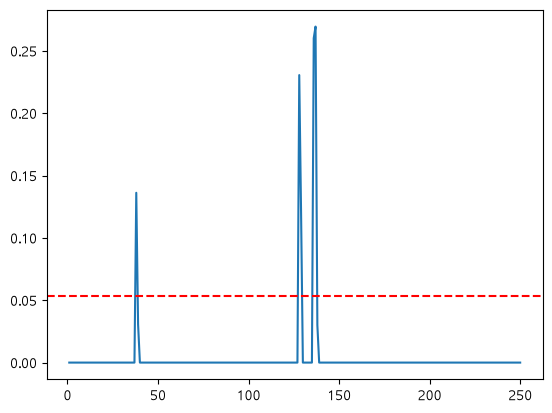

In [133]:
plt.plot(u2['시퀀스'],u2['컨베이어전류'])
plt.axhline(임계값, color='r', linestyle='--')


plt.show()

In [134]:
#정답확인  ??

임계값 : 0.0536 변화점 : 12


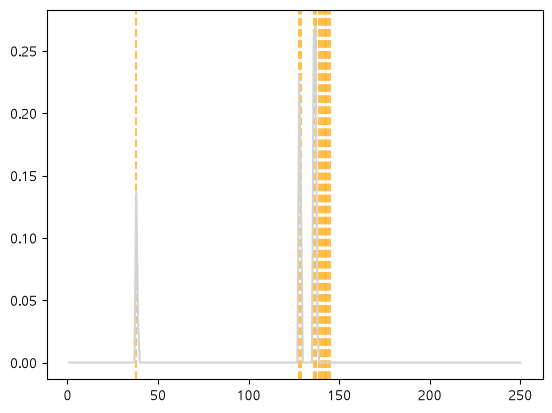

In [131]:
roll = u2['컨베이어전류'].rolling(10).mean()
resid = u2['컨베이어전류'] - roll
thr = 2 * resid.std()
u2['is_change'] = resid.abs() > thr
print('임계값 :', round(thr, 4), '변화점 :', int(u2['is_change'].sum()))   # 0.0536 / 12
for c in u2.loc[u2['is_change'], '시퀀스']:
    plt.axvline(c, color='orange', linestyle='--', alpha=0.7)
plt.plot(u2['시퀀스'], u2['컨베이어전류'], color='lightgray');

In [136]:
#실습7

In [145]:
def 잔차_임계값(col, window):
    roll = col.rolling(window).mean()
    잔차 = col - roll
    임계값= 잔차.std() * 2
    return (잔차.abs() > 임계값).sum()    

In [146]:
잔차_임계값(u2['컨베이어전류'], 10)

np.int64(12)

In [147]:
for i in [5,10,20]:
    print(잔차_임계값(u2['컨베이어전류'], i))

11
12
5


In [159]:
#실습7 

In [164]:
{i:i for i in (1,2,3)}

{1: 1, 2: 2, 3: 3}

In [158]:
def count_changes(series, window, k):
    r = series - series.rolling(window).mean()
    return int((r.abs() > k * r.std()).sum())
s = u2['컨베이어전류']
print({w: count_changes(s, w, 2) for w in (5, 10, 20)})       # {5:11, 10:12, 20:5}
print({k: count_changes(s, 10, k) for k in (1.5, 2.0, 3.0)})

{5: 11, 10: 12, 20: 5}
{1.5: 12, 2.0: 12, 3.0: 5}


In [165]:
s, w = u2['컨베이어전류'], 10
u2['ma'] = s.rolling(w).mean(); u2['std'] = s.rolling(w).std()
resid = s - u2['ma']; thr = 2 * resid.std()
u2['chg'] = resid.abs() > thr
half = u2['시퀀스'].median()
print('초반 /후반 변동성:', round(u2['std'].iloc[10:50].mean(), 4), round(u2['std'].iloc[150:].mean(), 4))  # 0.011 / 0.0
print('변화점 :', int(u2['chg'].sum()), '후반  비율 :', round(u2.loc[u2.시퀀스  > half, 'chg'].mean(), 2))  # 12 / 0.09

초반 /후반 변동성: 0.011 0.0
변화점 : 12 후반  비율 : 0.09


In [ ]:
#정규화 공식
# (x - x.mean()) / x.std()

In [181]:
data_path = "C:\\AI Equipment Failure Prediction\\data\\23_cmapss_unit1_timestamp.csv"
df = pd.read_csv(data_path)
df.head()

,timestamp,unit_number,time_cycles,sensor_2,sensor_3,sensor_4,sensor_7,sensor_11,sensor_15
0,2024-01-01 00:00:00,1,1,642.15,1591.29,1393.17,554.14,47.31,8.47
1,2024-01-01 01:00:00,1,2,641.96,1582.53,1401.36,554.46,48.04,8.49
2,2024-01-01 02:00:00,1,3,642.20,1591.05,1403.09,553.11,47.71,8.45
3,2024-01-01 03:00:00,1,4,642.46,1592.33,1416.91,554.68,47.33,8.47
4,2024-01-01 04:00:00,1,5,641.94,1584.72,1408.58,554.19,47.69,8.44


In [182]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 192 entries, 0 to 191
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   timestamp    192 non-null    str    
 1   unit_number  192 non-null    int64  
 2   time_cycles  192 non-null    int64  
 3   sensor_2     192 non-null    float64
 4   sensor_3     192 non-null    float64
 5   sensor_4     192 non-null    float64
 6   sensor_7     192 non-null    float64
 7   sensor_11    192 non-null    float64
 8   sensor_15    192 non-null    float64
dtypes: float64(6), int64(2), str(1)
memory usage: 17.2 KB


In [183]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

In [184]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 192 entries, 0 to 191
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   timestamp    192 non-null    datetime64[us]
 1   unit_number  192 non-null    int64         
 2   time_cycles  192 non-null    int64         
 3   sensor_2     192 non-null    float64       
 4   sensor_3     192 non-null    float64       
 5   sensor_4     192 non-null    float64       
 6   sensor_7     192 non-null    float64       
 7   sensor_11    192 non-null    float64       
 8   sensor_15    192 non-null    float64       
dtypes: datetime64[us](1), float64(6), int64(2)
memory usage: 13.6 KB


In [185]:
df.head()

,timestamp,unit_number,time_cycles,sensor_2,sensor_3,sensor_4,sensor_7,sensor_11,sensor_15
0,2024-01-01 00:00:00,1,1,642.15,1591.29,1393.17,554.14,47.31,8.47
1,2024-01-01 01:00:00,1,2,641.96,1582.53,1401.36,554.46,48.04,8.49
2,2024-01-01 02:00:00,1,3,642.20,1591.05,1403.09,553.11,47.71,8.45
3,2024-01-01 03:00:00,1,4,642.46,1592.33,1416.91,554.68,47.33,8.47
4,2024-01-01 04:00:00,1,5,641.94,1584.72,1408.58,554.19,47.69,8.44


In [190]:
ts=df.set_index('timestamp')
ts

,unit_number,time_cycles,sensor_2,sensor_3,sensor_4,sensor_7,sensor_11,sensor_15
timestamp,,,,,,,,
2024-01-01 00:00:00,1,1,642.15,1591.29,1393.17,554.14,47.31,8.47
2024-01-01 01:00:00,1,2,641.96,1582.53,1401.36,554.46,48.04,8.49
2024-01-01 02:00:00,1,3,642.20,1591.05,1403.09,553.11,47.71,8.45
2024-01-01 03:00:00,1,4,642.46,1592.33,1416.91,554.68,47.33,8.47
2024-01-01 04:00:00,1,5,641.94,1584.72,1408.58,554.19,47.69,8.44
...,...,...,...,...,...,...,...,...
2024-01-08 19:00:00,1,188,650.56,1612.22,1493.33,542.30,51.01,8.54
2024-01-08 20:00:00,1,189,649.86,1611.78,1453.52,544.70,50.27,8.95
2024-01-08 21:00:00,1,190,649.26,1616.90,1437.34,540.81,50.42,8.62


In [ ]:
#실습2 센서 : 3

In [196]:
ts_d=ts['sensor_3'].resample('D').mean()
print("하루 평균 :", len(ts_d))

하루 평균 : 8


In [200]:
ts_d.round(2).to_list()

[1592.12, 1590.92, 1593.35, 1597.82, 1603.7, 1610.59, 1614.09, 1628.51]

In [197]:
ts_6 = ts['sensor_3'].resample('6h').mean()
print('6시간 평균 :', len(ts_6))

6시간 평균 : 32


In [199]:
ts_d_rolling = ts_d.rolling(3).mean()
ts_d_rolling

timestamp
2024-01-01            NaN
2024-01-02            NaN
2024-01-03    1592.129722
2024-01-04    1594.028889
2024-01-05    1598.290833
2024-01-06    1604.036111
2024-01-07    1609.458611
2024-01-08    1617.726528
Freq: D, Name: sensor_3, dtype: float64

In [201]:
#정규화 공식 한글로 표현하면
#정규화 = (값 - 최소값) / (최대값 - 최소값)

In [206]:
#실습3 유닛넘버 2  / 2,7,10 / 괄후주의

In [252]:
df = pd.read_csv('C:\\AI Equipment Failure Prediction\\data\\23_cmapss_fd001_sample.csv')

In [253]:
df.head()

,unit_number,time_cycles,sensor_2,sensor_3,sensor_4,sensor_7,sensor_11,sensor_15
0,1,1,642.15,1591.29,1393.17,554.14,47.31,8.47
1,1,2,641.96,1582.53,1401.36,554.46,48.04,8.49
2,1,3,642.20,1591.05,1403.09,553.11,47.71,8.45
3,1,4,642.46,1592.33,1416.91,554.68,47.33,8.47
4,1,5,641.94,1584.72,1408.58,554.19,47.69,8.44


In [254]:
df['unit_number'].value_counts( sort=False )

unit_number
1    192
2    287
3    179
4    223
5    155
Name: count, dtype: int64

In [255]:
df.columns.to_list()

['unit_number',
 'time_cycles',
 'sensor_2',
 'sensor_3',
 'sensor_4',
 'sensor_7',
 'sensor_11',
 'sensor_15']

In [256]:
u2 = df['unit_number'] == 2
u2

0       False
1       False
2       False
3       False
4       False
        ...  
1031    False
1032    False
1033    False
1034    False
1035    False
Name: unit_number, Length: 1036, dtype: bool

In [257]:
u2 = df[df['unit_number'] == 2]
u2.head()

,unit_number,time_cycles,sensor_2,sensor_3,sensor_4,sensor_7,sensor_11,sensor_15
192,2,1,641.81,1594.41,1395.18,553.44,47.82,8.43
193,2,2,641.60,1593.98,1407.27,554.50,47.20,8.41
194,2,3,642.49,1597.05,1403.31,553.88,47.39,8.44
195,2,4,642.30,1591.09,1416.55,553.84,47.58,8.49
196,2,5,641.80,1582.23,1398.00,552.79,48.10,8.42


In [ ]:
 #2,7,11 /

In [258]:
cols = u2[['sensor_2', 'sensor_7', 'sensor_11']]

In [259]:
cols.head()

,sensor_2,sensor_7,sensor_11
192,641.81,553.44,47.82
193,641.60,554.50,47.20
194,642.49,553.88,47.39
195,642.30,553.84,47.58
196,641.80,552.79,48.10


In [260]:
standardized_cols = (cols-cols.min()) / (cols.max() - cols.min())
standardized_cols.head()

,sensor_2,sensor_7,sensor_11
192,0.048458,0.872162,0.168224
193,0.029956,0.935484,0.052336
194,0.108370,0.898447,0.087850
195,0.091630,0.896057,0.123364
196,0.047577,0.833333,0.220561


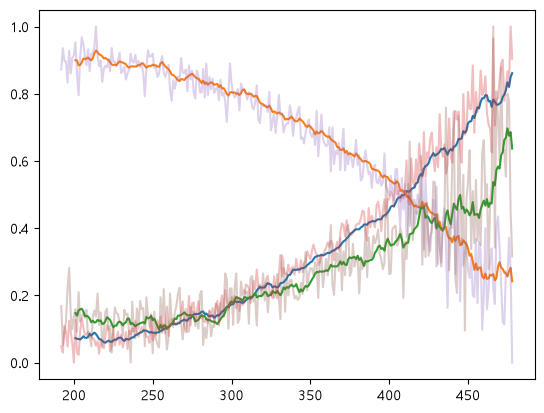

In [261]:
norm_ma = standardized_cols.rolling(window=10).mean()

plt.plot(norm_ma)
plt.plot(standardized_cols, alpha=0.3)

plt.show()

In [ ]:
#정규화 = (값 - 최소값) / (최대값 - 최소값)

In [262]:
#실습4

In [263]:
sensors = u2[['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_11', 'sensor_15']]

In [ ]:
sensors

In [ ]:
standardized_sensors = (sensors-sensors.min()) / (sensors.max() - sensors.min())
standardized_sensors.head()

In [268]:
ssr=standardized_sensors.rolling(window=10).mean()
ssr.shape   


(287, 6)

In [269]:
287/2

143.5

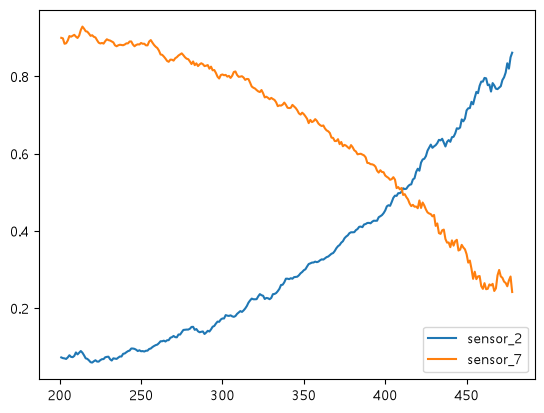

In [302]:
plt.plot(ssr[['sensor_2', 'sensor_7']])
plt.legend(['sensor_2', 'sensor_7'])
plt.show()

In [311]:
ssr.shape

(287, 6)

In [312]:
287/2

143.5

In [313]:
ssr_hm = ssr[:142].mean() #0~142까지 평균
ssr_tm = ssr[143:].mean() #143~끝까지 평균

In [316]:
ssr_hm-ssr_tm #초반후반의 변화폭

sensor_2    -0.385592
sensor_3    -0.246850
sensor_4    -0.202539
sensor_7     0.344556
sensor_11   -0.231471
sensor_15   -0.256711
dtype: float64

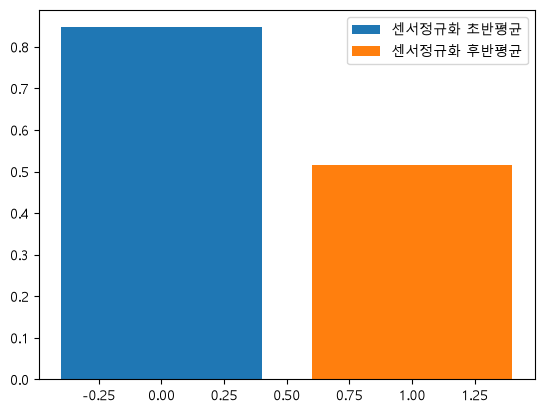

In [309]:
plt.bar(0, ssr_hm, label='센서정규화 초반평균')
plt.bar(1, ssr_tm, label='센서정규화 후반평균')
plt.legend()
plt.show()

In [279]:
센서전후차 = ssr_tm - ssr_hm 
센서전후차

sensor_2     0.385592
sensor_3     0.246850
sensor_4     0.202539
sensor_7    -0.344556
sensor_11    0.231471
sensor_15    0.256711
dtype: float64

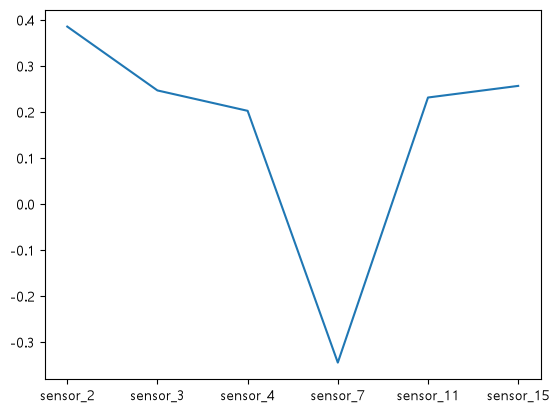

In [281]:
plt.plot(센서전후차)
plt.show()

In [357]:
#실습 5

In [327]:
sensors_corr=sensors.corr()
sensors_corr

,sensor_2,sensor_3,sensor_4,sensor_7,sensor_11,sensor_15
sensor_2,1.000000,0.831537,0.719078,-0.955467,0.838779,0.811637
sensor_3,0.831537,1.000000,0.624290,-0.818238,0.698998,0.701942
sensor_4,0.719078,0.624290,1.000000,-0.674783,0.576665,0.562824
sensor_7,-0.955467,-0.818238,-0.674783,1.000000,-0.809069,-0.811610
sensor_11,0.838779,0.698998,0.576665,-0.809069,1.000000,0.700046
sensor_15,0.811637,0.701942,0.562824,-0.811610,0.700046,1.000000


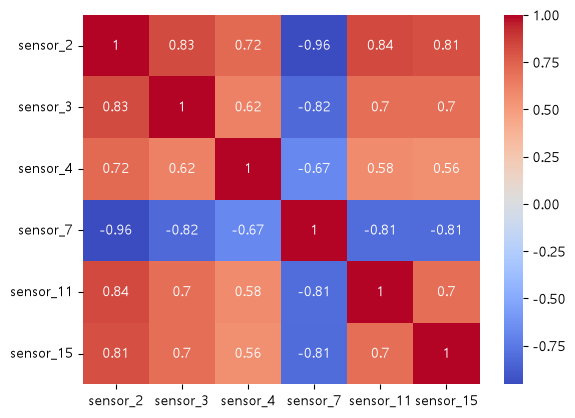

In [328]:
sns.heatmap(sensors_corr, annot=True, cmap="coolwarm")
plt.show()

In [326]:
#실습 6

In [330]:
sensors_corr

,sensor_2,sensor_3,sensor_4,sensor_7,sensor_11,sensor_15
sensor_2,1.000000,0.831537,0.719078,-0.955467,0.838779,0.811637
sensor_3,0.831537,1.000000,0.624290,-0.818238,0.698998,0.701942
sensor_4,0.719078,0.624290,1.000000,-0.674783,0.576665,0.562824
sensor_7,-0.955467,-0.818238,-0.674783,1.000000,-0.809069,-0.811610
sensor_11,0.838779,0.698998,0.576665,-0.809069,1.000000,0.700046
sensor_15,0.811637,0.701942,0.562824,-0.811610,0.700046,1.000000


In [333]:
sensors_corr_no_diag = sensors_corr.replace(1, 0)
sensors_corr_no_diag

,sensor_2,sensor_3,sensor_4,sensor_7,sensor_11,sensor_15
sensor_2,0.000000,0.831537,0.719078,-0.955467,0.838779,0.811637
sensor_3,0.831537,0.000000,0.624290,-0.818238,0.698998,0.701942
sensor_4,0.719078,0.624290,0.000000,-0.674783,0.576665,0.562824
sensor_7,-0.955467,-0.818238,-0.674783,0.000000,-0.809069,-0.811610
sensor_11,0.838779,0.698998,0.576665,-0.809069,0.000000,0.700046
sensor_15,0.811637,0.701942,0.562824,-0.811610,0.700046,0.000000


In [355]:
round(sensors_corr_no_diag.sort_values(by=sensors_corr_no_diag.max().idxmax(), ascending=False), 3 )

,sensor_2,sensor_3,sensor_4,sensor_7,sensor_11,sensor_15
sensor_11,0.839,0.699,0.577,-0.809,0.000,0.700
sensor_3,0.832,0.000,0.624,-0.818,0.699,0.702
sensor_15,0.812,0.702,0.563,-0.812,0.700,0.000
sensor_4,0.719,0.624,0.000,-0.675,0.577,0.563
sensor_2,0.000,0.832,0.719,-0.955,0.839,0.812
sensor_7,-0.955,-0.818,-0.675,0.000,-0.809,-0.812


In [356]:
#실습7

In [359]:
u2.head()

,unit_number,time_cycles,sensor_2,sensor_3,sensor_4,sensor_7,sensor_11,sensor_15
192,2,1,641.81,1594.41,1395.18,553.44,47.82,8.43
193,2,2,641.60,1593.98,1407.27,554.50,47.20,8.41
194,2,3,642.49,1597.05,1403.31,553.88,47.39,8.44
195,2,4,642.30,1591.09,1416.55,553.84,47.58,8.49
196,2,5,641.80,1582.23,1398.00,552.79,48.10,8.42


In [ ]:
#변화점은 "잔차가 큰 시점"

In [ ]:
def 잔차_임계값(col, window):
    roll = col.rolling(window).mean()
    잔차 = col - roll
    임계값= 잔차.std() * 2
    return (잔차.abs() > 임계값).sum()    

In [391]:
u2

,unit_number,time_cycles,sensor_2,sensor_3,sensor_4,sensor_7,sensor_11,sensor_15
192,2,1,641.81,1594.41,1395.18,553.44,47.82,8.43
193,2,2,641.60,1593.98,1407.27,554.50,47.20,8.41
194,2,3,642.49,1597.05,1403.31,553.88,47.39,8.44
195,2,4,642.30,1591.09,1416.55,553.84,47.58,8.49
196,2,5,641.80,1582.23,1398.00,552.79,48.10,8.42
...,...,...,...,...,...,...,...,...
474,2,283,650.58,1623.62,1463.83,543.39,49.88,8.90
475,2,284,651.10,1644.30,1472.86,543.11,51.20,8.65
476,2,285,650.62,1642.15,1394.58,545.06,51.10,8.80
477,2,286,652.61,1610.24,1420.86,543.44,49.33,8.45


In [401]:
u2_s2=u2['sensor_2']

In [429]:
이동평균 = u2_s2.rolling(10).mean()
이동표준편차 =  u2_s2.rolling(10).std()
잔차 = u2_s2 - 이동평균
임계값 = 잔차.std() * 2
변화점 = 잔차.abs() > 임계값

In [409]:
print('초반 변동성 :', round(이동표준편차.iloc[10:50].mean(), 3))

초반 변동성 : 0.319


In [410]:
print('후반 변동성 :', round(이동표준편차.iloc[150:].mean(), 3))

후반 변동성 : 0.516


In [433]:
print('변화점 개수 :', int(변화점.sum()))

변화점 개수 : 19


In [436]:
잔차

192      NaN
193      NaN
194      NaN
195      NaN
196      NaN
       ...  
474    0.126
475    0.372
476    0.051
477    1.707
478    0.482
Name: sensor_2, Length: 287, dtype: float64

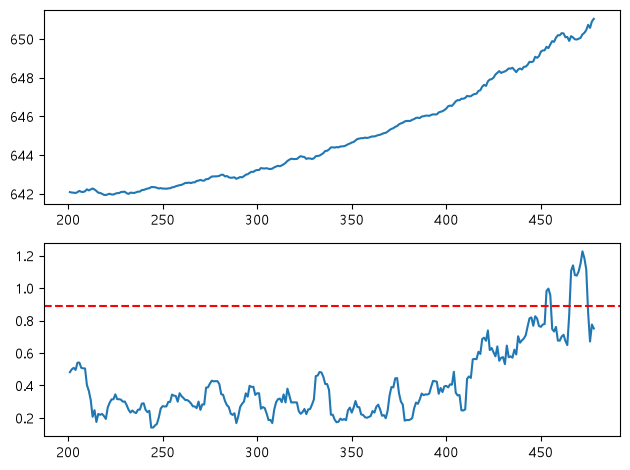

In [441]:
fig, [ax1, ax2] = plt.subplots(2, 1)
ax1.plot(이동평균)
ax2.plot(이동표준편차) 
ax2.axhline(임계값, color='r', linestyle='--')

plt.tight_layout()

plt.show()

In [362]:
 #iloc[10:50]을 초반, iloc[150:]

In [ ]:
#내데이터

In [363]:
import tensorflow as tf

In [373]:
matrix1 = tf.constant([[3, 4, 1], [0, 5, 2]])
matrix2 = tf.constant([[2, 0, 0 ], [1, 0, 5], [4,5,0]])
result = tf.matmul(matrix1, matrix2)
result

<tf.Tensor: shape=(2, 3), dtype=int32, numpy=
array([[14,  5, 20],
       [13, 10, 25]], dtype=int32)>